## EDA on Netflix

- Data Understand content trends by year, genre, and country.
- Bar chart of sales by region
- Pie chart of product categories
- Line chart showing monthly revenue trends


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("data_base/netflix_titles.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())

Dataset loaded successfully!
Dataset shape: (8807, 12)
  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-13     90 min   
1  September 24, 2021          

In [ ]:
print(df.isnull().sum())

df = df.drop_duplicates()

for col in ["director", "cast", "country", "rating", "duration"]:
    df[col] = df[col].fillna("Unknown")

df["date_added"] = pd.to_datetime(
    df["date_added"].str.strip(),
    errors="coerce"
)

print("Cleaned dataset shape:", df.shape)

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64
Cleaned dataset shape: (8807, 12)


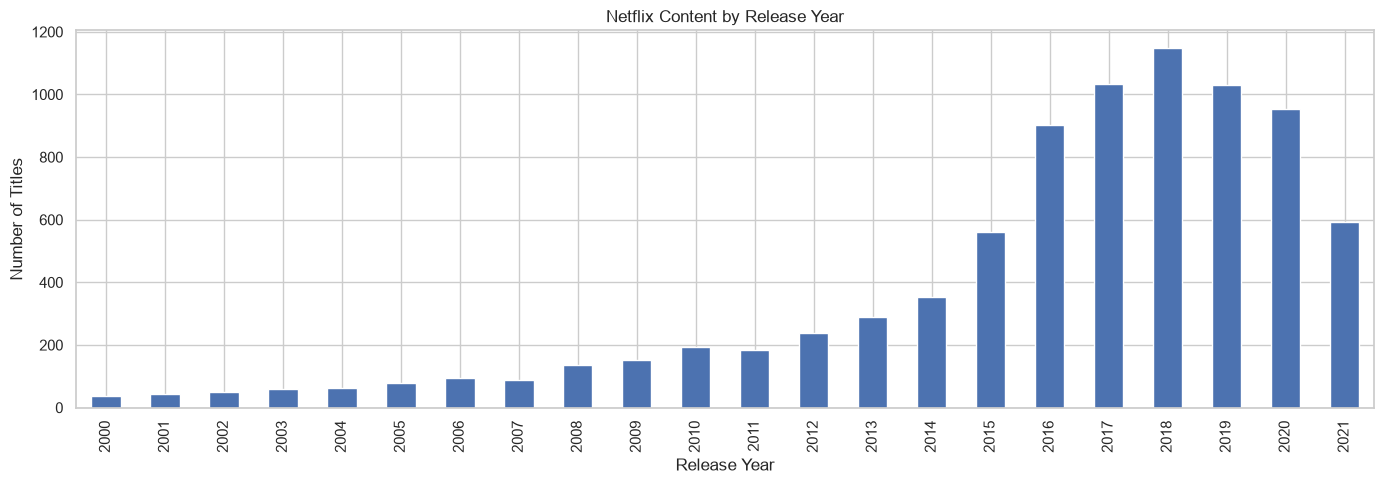

In [3]:
year_counts = df["release_year"].value_counts().sort_index()

year_counts = year_counts[year_counts.index >= 2000]

plt.figure(figsize=(14, 5))
year_counts.plot(kind="bar")

plt.title("Netflix Content by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

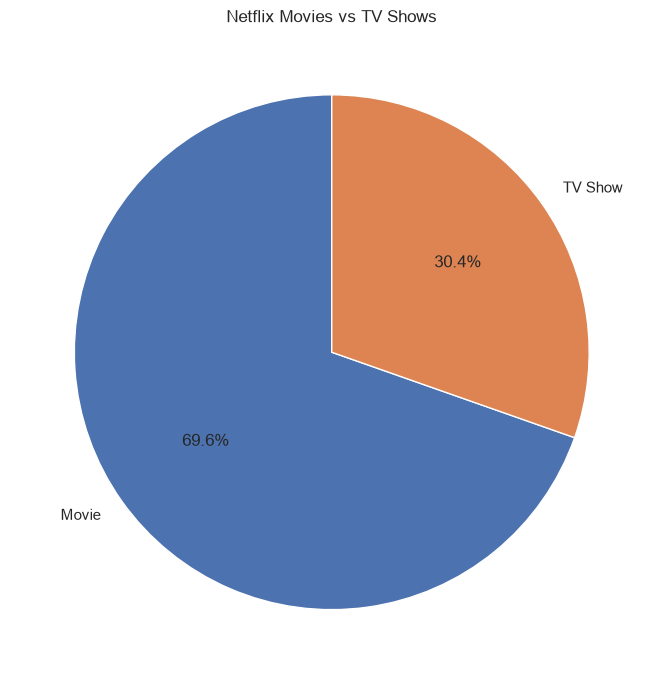

In [4]:
type_counts = df["type"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    type_counts.values,
    labels=type_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Netflix Movies vs TV Shows")
plt.tight_layout()
plt.show()

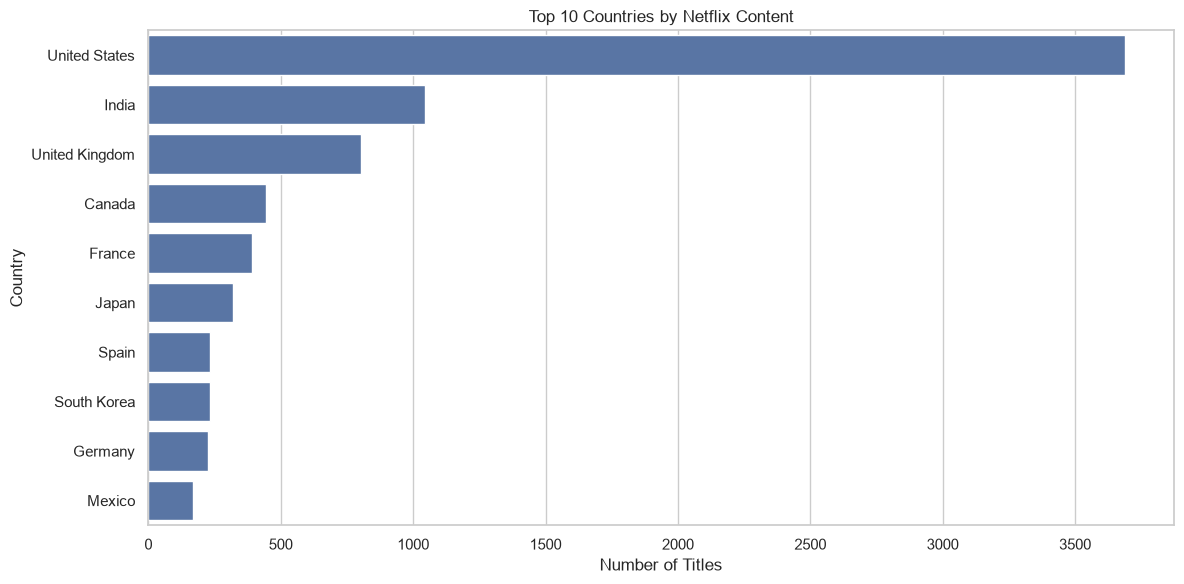

In [5]:
countries = df["country"].replace("Unknown", np.nan).dropna()
top_countries = countries.str.split(", ").explode().value_counts().head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_countries.values, y=top_countries.index)

plt.title("Top 10 Countries by Netflix Content")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

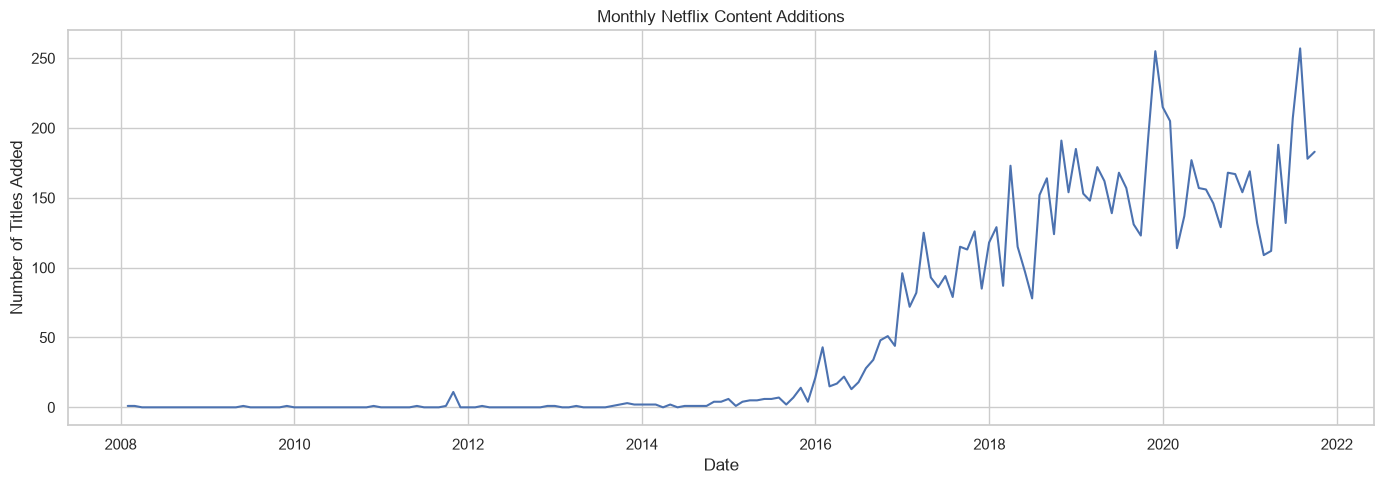

In [6]:
monthly = (
    df.dropna(subset=["date_added"])
      .set_index("date_added")
      .resample("ME")
      .size()
)

plt.figure(figsize=(14, 5))
plt.plot(monthly.index, monthly.values)

plt.title("Monthly Netflix Content Additions")
plt.xlabel("Date")
plt.ylabel("Number of Titles Added")
plt.tight_layout()
plt.show()